<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Your stations, our forecast 🇬🇷
### HNMS open station data × ECMWF open data · IFS 9 km · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/hnms_vs_ifs.ipynb)

HNMS publishes its automatic weather stations as open data on [data.gov.gr](https://data.gov.gr), every 5 minutes,
under CC BY 4.0. ECMWF publishes its 9 km forecast as open data under the same licence. This notebook puts the two
together: it fetches the last two days from every HNMS station and the ECMWF forecast for the same hours, draws them on
one map in one colour scale, and scores the forecast at each station.

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install. Everything runs on
Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| HNMS automatic weather stations ([data.gov.gr](https://data.gov.gr), EU High-Value Dataset) | 2 m temperature, every 5 minutes, last ~2 days | CC BY 4.0, © HNMS |
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), IFS 9 km | 2 m temperature, 00 UTC run, 3-hourly steps | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data,
and pandas.

*Press **Runtime → Run all**. The first run takes a few minutes, mostly installing the tools.*

> Not an official ECMWF or HNMS product: a worked example for the ECMWF liaison visit to HNMS, November 2026.
> Station positions come from WMO OSCAR/Surface where the station is a WMO station, otherwise from the place named in
> the dataset, which can be a few km out.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import io, datetime as dt
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm, ListedColormap
from ecmwf.opendata import Client

## 1 · Find the HNMS stations (data.gov.gr)

In [3]:
# data.gov.gr is a CKAN catalogue: one dataset per HNMS station, each with a CSV of 5-minute records
API = "https://data.gov.gr/api/3/action/package_search"
r = requests.get(API, params={"q": "Μετεωρολογικά Δεδομένα σταθμού", "rows": 200}, timeout=60).json()["result"]
files = {}
for p in r["results"]:
    if "ΕΜΥ" not in ((p.get("organization") or {}).get("title") or ""):        # ΕΜΥ = HNMS
        continue
    url = next(x["url"] for x in p["resources"] if x["url"].endswith(".dat"))
    files[url.rsplit("_", 1)[1][:3]] = url                                      # station_230.dat -> "230"

# positions and heights (the datasets carry none): a small table made for this notebook
stations = pd.read_csv("https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/greece/hnms_stations.csv", dtype={"id": str})
stations = stations[stations.id.isin(files)]
print(f"{len(files)} HNMS stations on data.gov.gr, {len(stations)} with a position")
stations.head()

76 HNMS stations on data.gov.gr, 75 with a position


,id,name,lat,lon,elev_m,located_by
0,230,VITSI,40.64820,21.38551,1746.0,place named in the dataset (approximate)
1,114,TANAGRA,38.33500,23.56300,138.0,WMO 16699
2,189,PARNITHA,38.08333,23.73333,1347.0,place named in the dataset (approximate)
3,116,ARAXOS,38.14900,21.42200,11.0,WMO 16687
4,007,KASTORIA,40.44900,21.27400,655.0,WMO 16614


## 2 · Fetch the last two days from every station

The files are large (all records since April), so the notebook asks for the end of each file only, with an HTTP range request.

In [4]:
TAIL = 900_000          # bytes from the end of each file: about 2.5 days of 5-minute records

def last_days(sid, tries=4):
    for k in range(tries):                                           # the server sometimes drops a connection
        try:
            return _last_days(sid)
        except Exception as err:
            last = err
    print(f"station {sid} skipped ({type(last).__name__})")
    return pd.DataFrame(columns=["id", "time", "t"])

def _last_days(sid):
    url = files[sid]
    s = requests.Session()
    header = s.get(url, headers={"Range": "bytes=0-3999"}, timeout=60).text.splitlines()[0].split(",")
    size = int(s.get(url, headers={"Range": "bytes=0-0"}, timeout=60).headers["Content-Range"].split("/")[1])
    tail = s.get(url, headers={"Range": f"bytes={max(0, size - TAIL)}-"}, timeout=120).text
    rows = tail.splitlines()[1:]                                    # the first line is cut in half
    d = pd.read_csv(io.StringIO("\n".join(rows)), names=header, na_values=["/////", "//////", "////", "///"],
                    usecols=["yyyyMMddHHmm", "Temp_Dry_5min"], dtype=str)
    d["time"] = pd.to_datetime(d.yyyyMMddHHmm, format="%Y%m%d%H%M")   # HNMS clock = UTC
    d["t"] = pd.to_numeric(d.Temp_Dry_5min, errors="coerce")
    d["id"] = sid
    return d[["id", "time", "t"]].dropna()

with ThreadPoolExecutor(8) as pool:                                  # eight at a time: about a minute
    obs = pd.concat(pool.map(last_days, stations.id))
obs = obs[(obs.t > -40) & (obs.t < 55)]
latest = obs.groupby("id").time.max()
print(f"{obs.id.nunique()} stations, {len(obs):,} records, newest {latest.max():%d %b %H:%M} UTC")

75 stations, 205,378 records, newest 22 Nov 08:55 UTC


## 3 · Get the ECMWF 9 km forecast for the same hours (open data)

In [5]:
# the newest 00 UTC run that started at least a day before the newest station data
last = latest.median().floor("h")
run = (last - pd.Timedelta(hours=27)).normalize()
STEPS = list(range(0, min(48, int((last - run) / pd.Timedelta(hours=1))) + 1, 3))
for SOURCE in ("ecmwf", "aws", "google"):                 # ECMWF first, then the cloud mirrors if it is busy
    try:
        Client(SOURCE).retrieve(date=run.to_pydatetime(), time=0, step=STEPS, stream="oper", type="fc",
                                levtype="sfc", param="2t", resol="0p1", target="t2m.grib2")   # 0p1 = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} did not answer ({type(err).__name__}), trying the next mirror")
x = ekd.from_source("file", "t2m.grib2").to_xarray()
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
x = x.sel(latitude=slice(42.2, 34.4), longitude=slice(19.0, 30.0))
t2m = x[list(x.data_vars)[0]] - 273.15
sdim = [d for d in t2m.dims if d not in ("latitude", "longitude")][0]
valid = [run + pd.Timedelta(hours=h) for h in STEPS]

# the model's own ground height and land-sea mask (step 0), to compare like with like at each station
Client(SOURCE).retrieve(date=run.to_pydatetime(), time=0, step=0, stream="oper", type="fc", levtype="sfc",
                        param=["z", "lsm"], resol="0p1", target="oro.grib2")
g = ekd.from_source("file", "oro.grib2").to_xarray().squeeze(drop=True)
g = g.assign_coords(longitude=((g.longitude + 180) % 360) - 180).sortby("longitude")
g = g.sel(latitude=t2m.latitude, longitude=t2m.longitude)
zmodel, land = (g.z / 9.80665).values, (g.lsm > 0.5).values
print(f"IFS 9 km, run {run:%d %b %Y} 00 UTC, steps {STEPS[0]}-{STEPS[-1]} h ({valid[0]:%d %b %H} to {valid[-1]:%d %b %H} UTC)")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


IFS 9 km, run 21 Nov 2026 00 UTC, steps 0-30 h (21 Nov 00 to 22 Nov 06 UTC)


In [6]:
# forecast at each station next to the 5-minute record nearest each forecast hour. Two standard steps make it fair:
#  1. use the nearest LAND grid point (a coastal station's nearest point can be sea), and
#  2. move the forecast from the grid point's height to the station's, at 6.5 °C per km.
LAPSE = 0.0065
lat, lon = t2m.latitude.values, t2m.longitude.values

def grid_point(la, lo):
    j, i = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
    near = [(np.hypot(lat[j + a] - la, (lon[i + b] - lo) * np.cos(np.radians(la))), j + a, i + b)
            for a in (-1, 0, 1) for b in (-1, 0, 1) if land[j + a, i + b]]
    return min(near)[1:] if near else (j, i)

pairs = []
for st in stations.itertuples():
    o = obs[obs.id == st.id].set_index("time").t.sort_index()
    if o.empty: continue
    j, i = grid_point(st.lat, st.lon)
    f = t2m.values[:, j, i] + LAPSE * (zmodel[j, i] - st.elev_m)
    for h, v, fc in zip(STEPS, valid, f):
        k = o.index.get_indexer([v], method="nearest", tolerance=pd.Timedelta("10min"))[0]
        if k >= 0:
            pairs.append(dict(id=st.id, name=st.name.title(), step=h, valid=v, forecast=float(fc),
                              station=float(o.iloc[k]), elev=st.elev_m, model_elev=float(zmodel[j, i])))
pairs = pd.DataFrame(pairs); pairs["error"] = pairs.forecast - pairs.station
print(f"{len(pairs):,} forecast-station pairs at {pairs.id.nunique()} stations")
print(f"Mean error (forecast - station): {pairs.error.mean():+.2f} °C   mean absolute error: {pairs.error.abs().mean():.2f} °C   "
      f"within 2 °C: {100 * (pairs.error.abs() <= 2).mean():.0f} %")

767 forecast-station pairs at 71 stations
Mean error (forecast - station): +0.58 °C   mean absolute error: 1.69 °C   within 2 °C: 68 %


## 4 · One map, one colour scale

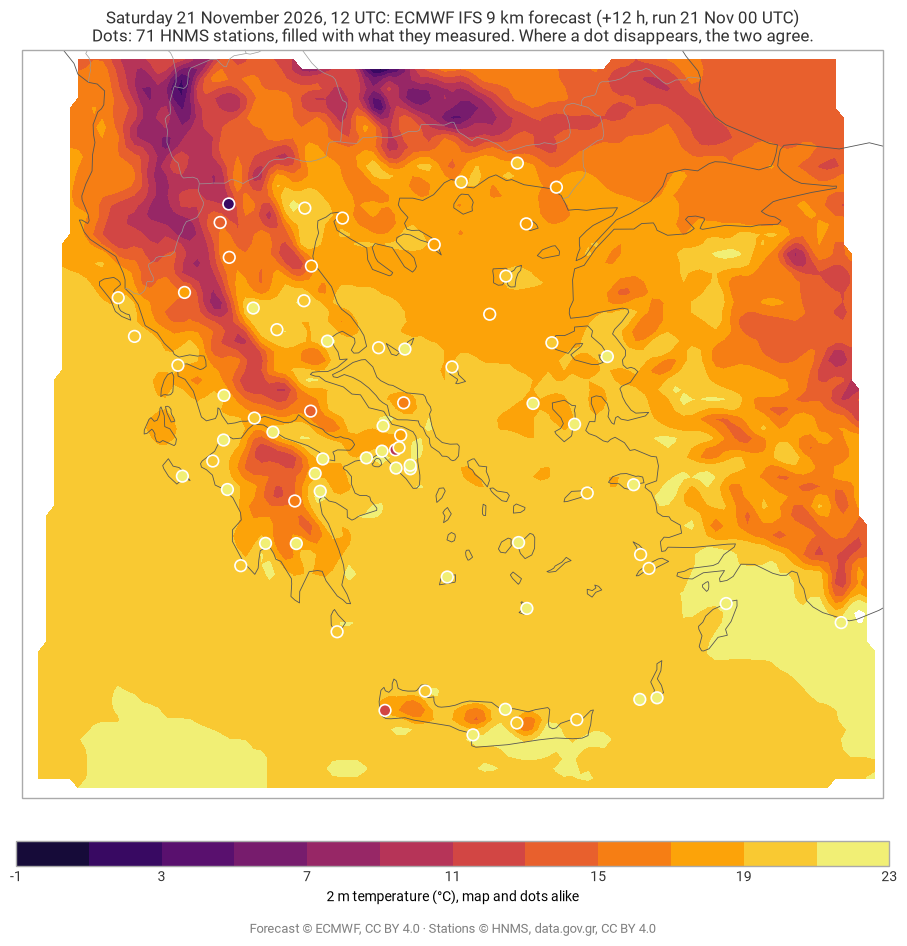

In [7]:
# one hour, one colour scale: the forecast as the map, each station as a dot filled with what it measured
WHEN = valid.index(max(v for v in valid if v.hour == 12))       # the last 12 UTC with both
field = t2m.isel({sdim: WHEN})
now = pairs[pairs.valid == valid[WHEN]].merge(stations[["id", "lat", "lon"]], on="id")
lo, hi = np.floor(min(field.min(), now.station.min())), np.ceil(max(field.max(), now.station.max()))
levels = np.arange(lo, hi + 1, 1 if hi - lo < 16 else 2)
colors = plt.get_cmap("inferno")(np.linspace(0.1, 0.95, len(levels) - 1))
style = ekp.styles.Style(levels=levels, colors=[tuple(c) for c in colors], extend="neither")

chart = ekp.Map(domain=[19.0, 30.0, 34.4, 42.2], figsize=(11, 9))
chart.contourf(field, style=style)
chart.coastlines(linewidth=0.6); chart.borders(linewidth=0.5)
cmap, norm = ListedColormap(colors), BoundaryNorm(levels, len(colors))
chart.ax.scatter(now.lon, now.lat, c=now.station, cmap=cmap, norm=norm, s=70, edgecolors="white", linewidths=1.2,
                 zorder=10, transform=ccrs.PlateCarree())
chart.legend(label="2 m temperature (°C), map and dots alike")
chart.title(f"{valid[WHEN]:%A %d %B %Y}, 12 UTC: ECMWF IFS 9 km forecast (+{STEPS[WHEN]} h, run {run:%d %b} 00 UTC)\n"
            f"Dots: {len(now)} HNMS stations, filled with what they measured. Where a dot disappears, the two agree.",
            fontsize=12)
chart.attribution("Forecast © ECMWF, CC BY 4.0 · Stations © HNMS, data.gov.gr, CC BY 4.0")
chart.save("hnms_vs_ifs_map.png")
chart.show()

### How the forecast did at each station

In [8]:
# how the forecast did at each station over the two days (positive = forecast warmer than the station)
table = (pairs.groupby("name")
              .agg(height_m=("elev", "first"), model_height_m=("model_elev", "first"), pairs=("error", "size"),
                   mean_error=("error", "mean"), mean_abs_error=("error", lambda e: e.abs().mean()))
              .round(1).sort_values("mean_error"))
table

,height_m,model_height_m,pairs,mean_error,mean_abs_error
name,,,,,
Elefsina,26.0,325.8,11,-2.6,2.6
Aigio,0.0,330.6,11,-2.3,2.3
Mytilene,4.0,136.5,11,-2.0,2.0
Sparta,167.0,618.4,11,-1.9,1.9
Nafpaktos,0.0,284.4,11,-1.8,1.8
...,...,...,...,...,...
Agrinio,11.0,123.4,11,2.4,2.9
Argos,2.0,179.9,11,2.7,3.1
Araxos,11.0,99.0,11,2.9,3.5


The scores already allow for height: the forecast was moved from the grid point's height (`model_height_m`)
to the station's (`height_m`). What remains is mostly local: a valley floor that collects cold air at night, a sea
breeze, a station in a town, or a position that is only approximate (see the station table). In step 3, set
`LAPSE = 0` to see how much the height correction matters at the mountain stations.

### One station, hour by hour

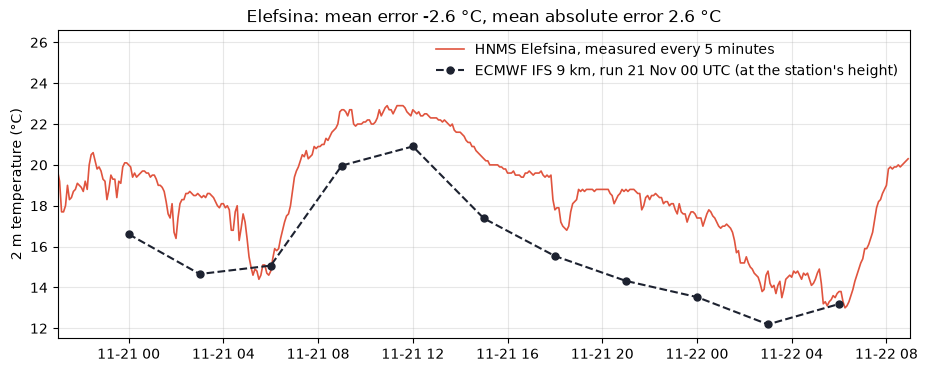

In [9]:
STATION = "ELEFSINA"          # any name from the table, e.g. "IRAKLEIO", "LARISA", "VITSI", "NAXOS"
sid = stations.set_index("name").id[STATION]
o = obs[obs.id == sid]; p = pairs[pairs.id == sid]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(o.time, o.t, color="#e0543e", lw=1.2, label=f"HNMS {STATION.title()}, measured every 5 minutes")
ax.plot(p.valid, p.forecast, "o--", color="#1d2230", lw=1.5, ms=5,
        label=f"ECMWF IFS 9 km, run {run:%d %b} 00 UTC (at the station's height)")
ax.set_xlim(valid[0] - pd.Timedelta(hours=3), valid[-1] + pd.Timedelta(hours=3))
ax.set_ylabel("2 m temperature (°C)"); ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.set_title(f"{STATION.title()}: mean error {p.error.mean():+.1f} °C, mean absolute error {p.error.abs().mean():.1f} °C")
plt.show()

## 5 · Your turn 🌍

- **Another station:** change `STATION`. Try a mountain station (`VITSI`, `PARNITHA`) with `LAPSE = 0` and without.
- **The machine-learning forecast:** in step 2, add `model="aifs-single"` and remove `resol="0p1"` (AIFS Single is
  open data at 0.25°). Then run steps 3-4 again and compare the scores.
- **Wind:** the HNMS files also hold `Wind_Speed_Avg_5min` and `Wind_Dir_Avg_5min`; the forecast has `10u` and `10v`.
- **More history:** raise `TAIL`. Each file holds 5-minute records from April 2026 (about 22 MB).

### Data & licence
**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
**HNMS station data**, CC BY 4.0: `© HNMS (Hellenic National Meteorological Service) · Source: data.gov.gr`.
No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [HNMS](https://www.emy.gr) ·
[data.gov.gr](https://data.gov.gr) · [earthkit](https://earthkit.ecmwf.int)